In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from shapely.geometry import LineString, Point
from shapely.strtree import STRtree
from pyproj import CRS, Transformer

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
TRAIN_DIR = PROJECT_ROOT / "data" / "processed" / "train"
OUTPUT_DIR = PROJECT_ROOT / "data" / "interim" / "route_quality"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
TRIP_IDS = ["00000033", "00000054"]

In [2]:
def load_trip(trip_id):
    folder = TRAIN_DIR / trip_id
    return {
        "track": pd.read_csv(folder / "track.csv"),
        "nodes": pd.read_csv(folder / "nodes.csv"),
        "arcs": pd.read_csv(folder / "arcs.csv"),
        "route": pd.read_csv(folder / "route.csv").sort_values("route_step").reset_index(drop=True)
    }

def make_transformer(track):
    crs = CRS.from_proj4(
        f"+proj=aeqd +lat_0={track.latitude.median()} +lon_0={track.longitude.median()} +datum=WGS84 +units=m +no_defs"
    )
    return Transformer.from_crs("EPSG:4326", crs, always_xy=True)

def make_geometries(nodes, arcs, transformer):
    nx, ny = transformer.transform(nodes.longitude.to_numpy(), nodes.latitude.to_numpy())
    geoms = [
        LineString([(nx[int(u)], ny[int(u)]), (nx[int(v)], ny[int(v)])])
        for u, v in zip(arcs.from_node_id, arcs.to_node_id)
    ]
    return geoms, nx, ny

def nearest_distances(points, geometries):
    tree = STRtree(geometries)
    indices, distances = tree.query_nearest(points, return_distance=True, all_matches=False)
    result = np.full(len(points), np.nan)
    result[indices[0]] = distances
    return result

In [3]:
def inspect_trip(trip_id):
    trip = load_trip(trip_id)
    track, nodes, arcs, route = trip["track"], trip["nodes"], trip["arcs"], trip["route"]
    transformer = make_transformer(track)
    gx, gy = transformer.transform(track.longitude.to_numpy(), track.latitude.to_numpy())
    points = [Point(x, y) for x, y in zip(gx, gy)]

    all_geometries, nx, ny = make_geometries(nodes, arcs, transformer)
    route_arcs = arcs.set_index("arc_id").loc[route.arc_id.to_numpy(dtype=int)]
    route_geometries = [
        LineString([(nx[int(u)], ny[int(u)]), (nx[int(v)], ny[int(v)])])
        for u, v in zip(route_arcs.from_node_id, route_arcs.to_node_id)
    ]

    route_distance = nearest_distances(points, route_geometries)
    network_distance = nearest_distances(points, all_geometries)
    result = pd.DataFrame({
        "observation_pos": np.arange(len(track)),
        "route_distance_m": route_distance,
        "network_distance_m": network_distance
    })
    result["route_far_network_near"] = (result.route_distance_m > 100) & (result.network_distance_m <= 30)
    result["route_and_network_far"] = (result.route_distance_m > 100) & (result.network_distance_m > 100)
    return trip, gx, gy, route_geometries, all_geometries, result

In [4]:
reviews = {}
summary_rows = []
for trip_id in TRIP_IDS:
    trip, gx, gy, route_geometries, all_geometries, distances = inspect_trip(trip_id)
    reviews[trip_id] = (trip, gx, gy, route_geometries, all_geometries, distances)
    summary_rows.append({
        "trip_id": trip_id,
        "observations": len(distances),
        "route_median_m": distances.route_distance_m.median(),
        "route_p95_m": distances.route_distance_m.quantile(.95),
        "route_within_30m": (distances.route_distance_m <= 30).mean(),
        "route_within_100m": (distances.route_distance_m <= 100).mean(),
        "network_median_m": distances.network_distance_m.median(),
        "network_p95_m": distances.network_distance_m.quantile(.95),
        "network_within_30m": (distances.network_distance_m <= 30).mean(),
        "network_within_100m": (distances.network_distance_m <= 100).mean(),
        "route_far_network_near_pct": distances.route_far_network_near.mean(),
        "route_and_network_far_pct": distances.route_and_network_far.mean()
    })
    distances.to_csv(OUTPUT_DIR / f"trip_{trip_id}_distance_audit.csv", index=False)

quality_summary = pd.DataFrame(summary_rows)
display(quality_summary)
quality_summary.to_csv(OUTPUT_DIR / "trip_quality_review_corrected.csv", index=False)

,trip_id,observations,route_median_m,route_p95_m,route_within_30m,route_within_100m,network_median_m,network_p95_m,network_within_30m,network_within_100m,route_far_network_near_pct,route_and_network_far_pct
0,00000033,5844,122.421322,142.068025,0.290554,0.490418,6.998837,30.208246,0.948665,1.000000,0.506502,0.000000
1,00000054,19313,138.616262,210.093911,0.114534,0.163413,84.175749,100.684367,0.140475,0.942733,0.000052,0.057267


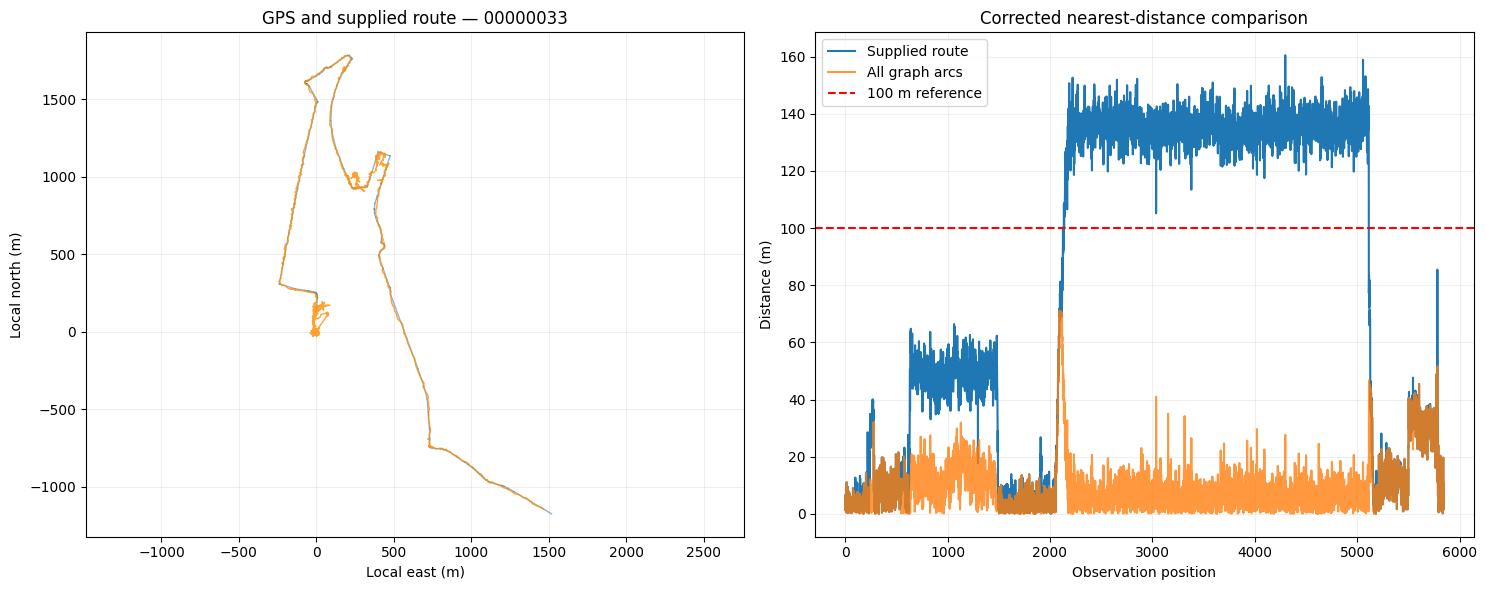

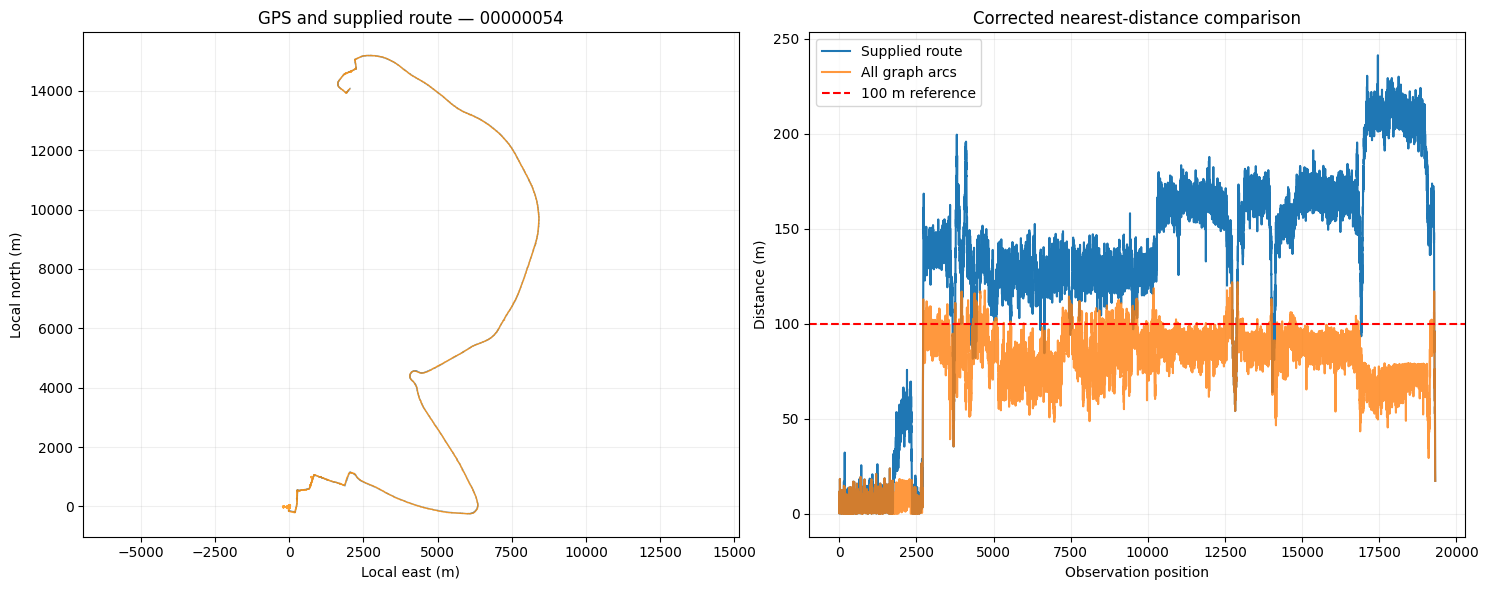

In [5]:
for trip_id, (trip, gx, gy, route_geometries, all_geometries, distances) in reviews.items():
    fig, axes = plt.subplots(1, 2, figsize=(15, 6))
    for geom in route_geometries:
        x, y = geom.xy
        axes[0].plot(x, y, color="steelblue", linewidth=1.0, alpha=.6)
    axes[0].plot(gx, gy, color="darkorange", linewidth=1.0, alpha=.8)
    axes[0].set_aspect("equal", adjustable="datalim")
    axes[0].set_title(f"GPS and supplied route — {trip_id}")
    axes[0].set_xlabel("Local east (m)")
    axes[0].set_ylabel("Local north (m)")
    axes[0].grid(alpha=.2)

    axes[1].plot(distances.observation_pos, distances.route_distance_m, label="Supplied route")
    axes[1].plot(distances.observation_pos, distances.network_distance_m, label="All graph arcs", alpha=.8)
    axes[1].axhline(100, color="red", linestyle="--", label="100 m reference")
    axes[1].set_title("Corrected nearest-distance comparison")
    axes[1].set_xlabel("Observation position")
    axes[1].set_ylabel("Distance (m)")
    axes[1].legend()
    axes[1].grid(alpha=.2)
    plt.tight_layout()
    plt.show()